<a href="https://colab.research.google.com/github/PallaviRajaa/Statistical-Foundation-of-Data-Science/blob/main/Stats9/StatisticsA9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

iris = load_iris()



Exploratory Data Analysis (EDA)

In [ ]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(
    iris.target, iris.target_names
)


print("First five rows:")
print(df.head())

print("\nStatistical description:")
print(df.describe())

print("\nGroup by species:")
print(df.groupby('species', observed=True).mean(numeric_only=True))

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Statistical description:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.80

The load_iris() function loads the Iris dataset, and pd.DataFrame() converts it into a tabular format with appropriate column names. The head() function displays the first five rows, while describe() provides statistical information such as mean, standard deviation, minimum, and maximum values. The groupby() function calculates the average measurements for each flower species. Finally, info() and isnull().sum() help us check the data types and missing values in the dataset.

Feature Scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('species', axis=1)
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (120, 4)
Testing set size: (30, 4)


The train_test_split() function divides the dataset into training and testing sets, with 80% used for training and 20% for testing. The input features are stored in X, and the target species labels are stored in y. The StandardScaler() function standardizes the features so that they have comparable scales. The fit_transform() function scales the training data, while transform() applies the same scaling to the test data. The shape attribute displays the number of records and features in each set.

Training the KNN Model


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("Actual values:", y_test)
print("Predicted values:", y_pred)

Actual values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


The KNeighborsClassifier(n_neighbors=5) function creates a KNN classification model that considers the five nearest neighbors. The fit(X_train, y_train) function trains the model using the scaled training features and their corresponding species labels. The predict(X_test) function predicts the species of flowers in the test dataset.

Confusion Matrix and Accuracy Score

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Accuracy Score: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


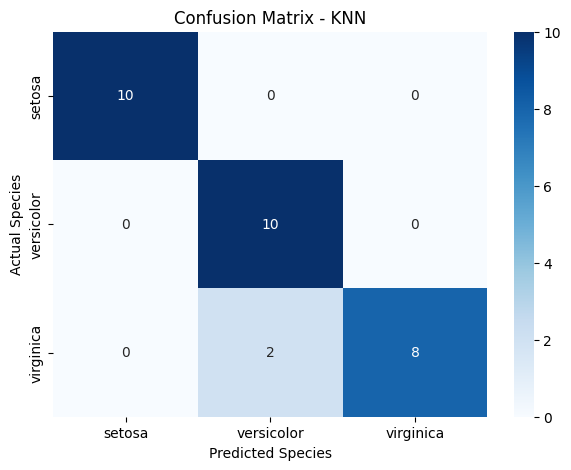

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy Score:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - KNN")
plt.show()

The confusion_matrix(y_test, y_pred) function compares the actual species labels with the predicted labels and displays the number of correct and incorrect classifications. The accuracy_score() function calculates the proportion of correctly predicted samples. Multiplying the accuracy by 100 converts it into a percentage. The sns.heatmap() function visualizes the confusion matrix using colors and numerical values, making it easier to understand the classification performance for each species.


Classification Report

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



- Precision: Out of all samples predicted as a particular species, how many actually belong to that species?
- Recall: Out of all actual samples belonging to a species, how many were correctly identified?
- F1-score: The harmonic mean of precision and recall.
- Support: Number of actual test samples belonging to each species.
A higher precision, recall, and F1-score generally indicate better classification performance. Since the test set is stratified, it contains 10 samples of each species.

Comparing Error Rate with K Values

In [ ]:
error_rates = []

for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    error = 1 - accuracy_score(y_test, predictions)
    error_rates.append(error)

    print("K =", k, "Error Rate =", round(error, 4))

K = 1 Error Rate = 0.0333
K = 2 Error Rate = 0.0667
K = 3 Error Rate = 0.0667
K = 4 Error Rate = 0.0667
K = 5 Error Rate = 0.0667
K = 6 Error Rate = 0.0667
K = 7 Error Rate = 0.0333
K = 8 Error Rate = 0.0667
K = 9 Error Rate = 0.0333
K = 10 Error Rate = 0.0333
K = 11 Error Rate = 0.0333
K = 12 Error Rate = 0.0333
K = 13 Error Rate = 0.0333
K = 14 Error Rate = 0.0333
K = 15 Error Rate = 0.0333
K = 16 Error Rate = 0.0333
K = 17 Error Rate = 0.0333
K = 18 Error Rate = 0.0333
K = 19 Error Rate = 0.0333
K = 20 Error Rate = 0.0333


The error_rates = [] statement creates an empty list to store the error rates for different K values. The for loop tests K values from 1 to 20, creating and training a separate KNN model for each value. The predict() function generates test predictions, and 1 - accuracy_score() calculates the error rate. The append() function stores each error rate in the list, while print() displays the results for comparison.


Plot the Error Values Against K Values

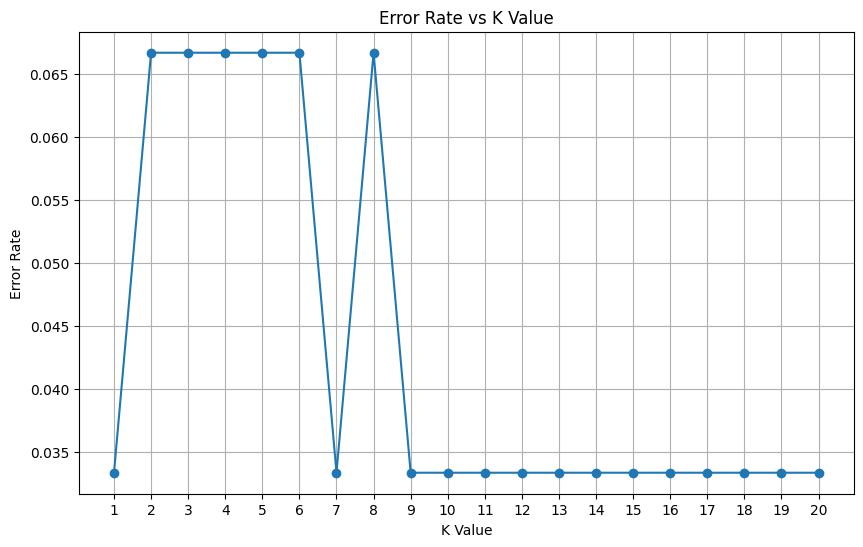

In [ ]:
k_values = range(1, 21)

plt.figure(figsize=(10, 6))

plt.plot(
    k_values,
    error_rates,
    marker='o',
    linestyle='-'
)

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs K Value")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

The k_values = range(1, 21) statement creates a sequence of K values from 1 to 20. The plt.plot() function draws a line graph showing the relationship between K values and their corresponding error rates. The xlabel(), ylabel(), and title() functions add labels and a title to the graph. The xticks() and grid() functions improve readability, while plt.show() displays the graph. The lowest point indicates the K value with the minimum observed error rate.

Finding the Best K

In [ ]:

best_index = error_rates.index(min(error_rates))

best_k = best_index + 1

print("Best K Value:", best_k)
print("Minimum Error Rate:", min(error_rates))
print("Best Accuracy:", (1 - min(error_rates)) * 100, "%")

Best K Value: 1
Minimum Error Rate: 0.033333333333333326
Best Accuracy: 96.66666666666667 %


The min(error_rates) function finds the smallest error rate from the list, and index() identifies its position. Adding 1 to this index gives the corresponding K value because Python list indexing starts at zero. The program then displays the best K value and its minimum error rate. Finally, (1 - min(error_rates)) * 100 calculates the corresponding accuracy percentage. This identifies the best-performing K among the tested values on the selected test set.


Visualizing the Test Results of KNN


The KNeighborsClassifier(n_neighbors=best_k) function creates the final model using the selected K value, and fit() trains it on the training data. The predict() function generates the predicted species, while inverse_transform() converts the scaled test features back to their original measurements. The scatter() function creates graphs comparing actual and predicted species using petal length and petal width. Finally, plt.show() displays both graphs, and accuracy_score() calculates the final test accuracy as a percentage.

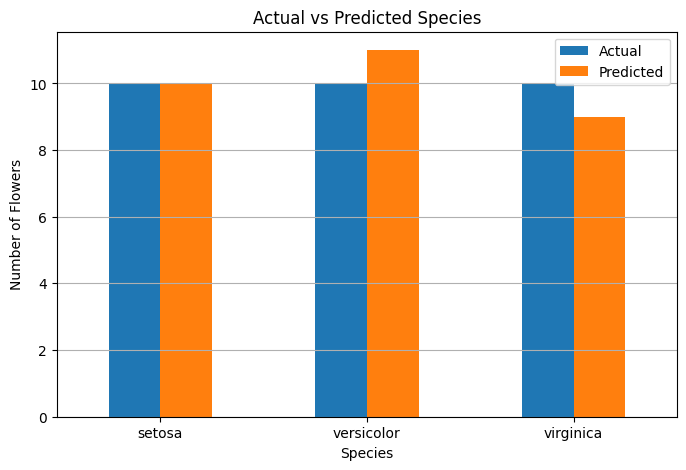

In [ ]:
# Train the final model using the best K
final_knn = KNeighborsClassifier(n_neighbors=best_k)

final_knn.fit(X_train_scaled, y_train)

final_pred = final_knn.predict(X_test_scaled)

# Count actual and predicted species
actual_counts = pd.Series(y_test).value_counts().sort_index()

predicted_counts = pd.Series(final_pred).value_counts().sort_index()

# Create comparison DataFrame
results = pd.DataFrame({
    "Actual": actual_counts,
    "Predicted": predicted_counts
})

# Replace numerical labels with species names
results.index = iris.target_names

# Plot bar graph
results.plot(kind="bar", figsize=(8, 5))

plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.title("Actual vs Predicted Species")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")

plt.show()